In [5]:
# Resolve the CDR dataset and the workspace bucket
cdr    <- trimws(tail(system("wb resource resolve --id=C2024Q3R9", intern = TRUE), 1))
bucket <- trimws(tail(system("wb resource resolve --id=rw-migration-aou-rw-6f1dba72", intern = TRUE), 1))

cdr     # expect something like "project-id.C2024Q3R9" (exactly one dot)
bucket  # expect "gs://..."

Sys.setenv(WORKSPACE_CDR = cdr, WORKSPACE_BUCKET = bucket)

[1] "wb-silky-artichoke-2408.C2024Q3R9"

[1] "gs://rw-migration-aou-rw-6f1dba72"

In [6]:
BASE <- "/home/jupyter/workspace/rw-migration-aou-rw-6f1dba72/workspaces"
MISS <- file.path(BASE, "temporaldigitalhealthphenotyping/final_missing")
source(file.path(MISS, "load_missingness.R")); load_missingness(MISS)

EXPORT_DATE <- "20261031"      # the 16 exports of the full-pool selection (selection/selection_cells.R, Cell 9)
FINAL_PID   <- file.path(BASE, "result/selection/20261031/final_pid_base.txt")
CCI_FILE    <- file.path(BASE, "result/selection/20261031/cci.txt")      # CCI with age at the first record
L1_DIR      <- file.path(BASE, "result/final_missing/L1")
OUT_DIR     <- file.path(BASE, "result/final_missing/results")
OVERLAP_POLICY <- "exclude"

cfg <- make_config(list(export  = list(date = EXPORT_DATE),
                        overlap = list(policy = OVERLAP_POLICY)))

cat("bucket :", cfg$export$bucket, "\nowner  :", cfg$export$owner, "\n")
cat("CDR    :", cfg$export$cdr, "\nbilling:", cfg$export$billing, "\n")
stopifnot("final_pid.txt not found - fix FINAL_PID"   = file.exists(FINAL_PID),
          "CCI file not found - fix CCI_FILE"         = file.exists(CCI_FILE),
          "WORKSPACE_BUCKET / OWNER_EMAIL not set"    = nzchar(cfg$export$bucket) && nzchar(cfg$export$owner))

bucket : gs://rw-migration-aou-rw-6f1dba72 
owner  : zqiu@researchallofus.org 
CDR    : wb-silky-artichoke-2408.C2024Q3R9 
billing: wb-dazzling-artichoke-8134 


In [3]:
need <- c("data.table", "lme4", "ordinal", "survival", "sandwich", "ggplot2", "rstatix", "ggpubr", "bigrquery")
print(sapply(need, requireNamespace, quietly = TRUE))   # any FALSE: install.packages("name")
#install.packages("sandwich")

Registered S3 method overwritten by 'car':
  method           from
  na.action.merMod lme4



data.table       lme4    ordinal   survival   sandwich    ggplot2    rstatix 
      TRUE       TRUE       TRUE       TRUE       TRUE       TRUE       TRUE 
    ggpubr  bigrquery 
      TRUE       TRUE 


In [4]:
cfg_demo <- make_config(list(boot = list(B = 50L)))
inp_demo <- simulate_inputs(cfg_demo)
res_demo <- run_missingness_pipeline(inp_demo$day_tables, inp_demo$persons, cfg_demo,
                                     file.path(tempdir(), "demo"),
                                     stages = c("missingness", "temporal", "descriptive", "onset"),
                                     onset_roles = "primary")
print(res_demo$primary_test[, .(stream, or = round(or, 2), p_holm)])    # expect or about 1.6-1.7 for all three

21:48:41 | hr: filled 6358 absent zone minute/calorie value(s) with 0

21:48:41 | hr: 1 day(s) have total zone minutes > 1440

Warning message:
“sleep: selection rule not fully met (n<21 days: 0; <70% observed: 4; gap>14 days: 0). Results are labelled as given.”
21:50:10 | [run] onset / activity / activity|joint|k1|adj  (session 0.6 GB, free 21.4 GB)

21:50:14 | [run] onset_extra / activity / vif  (session 0.6 GB, free 21.4 GB)

21:50:14 | [run] onset_extra / activity / cohort_interaction  (session 0.6 GB, free 21.4 GB)

21:50:21 | [run] onset_extra / activity / cohort_Insomnia  (session 0.6 GB, free 21.0 GB)

21:50:22 | [run] onset_extra / activity / cohort_Diabetes  (session 0.6 GB, free 21.2 GB)

21:50:24 | [run] onset_extra / activity / cohort_Healthy  (session 0.6 GB, free 21.1 GB)

21:50:26 | [run] onset_extra / activity / cohort_Prostate  (session 0.6 GB, free 21.1 GB)

21:50:26 | [run] onset_extra / activity / risk_unadjusted  (session 0.6 GB, free 21.4 GB)

21:50:29 | [run] on

     stream    or       p_holm
     <char> <num>        <num>
1: activity  1.59 6.207585e-22
2:       hr  1.73 2.115434e-41
3:    sleep  1.70 2.227767e-51


In [4]:
# ==== CELL 5
final_pid <- read_final_pid(FINAL_PID)
stopifnot("cohort names in final_pid must be Insomnia / Diabetes / Healthy / Prostate" =
            all(final_pid$cohort %in% cfg$cohorts))
print(final_pid[, .N, by = cohort])
ov <- resolve_cohort_overlap(final_pid, OVERLAP_POLICY, cfg$overlap$priority)
cat("unique people:", ov$n_unique_people, "| in more than one cohort:", length(ov$overlap_ids),
    "| kept with policy", OVERLAP_POLICY, ":", ov$n_kept, "\n")
print(ov$overlap)                      

     cohort     N
     <char> <int>
1: Diabetes  1306
2:  Healthy  6381
3: Insomnia  1388
4: Prostate   253
unique people: 8939 | in more than one cohort: 386 | kept with policy exclude : 8553 
                      combination n_people
                           <char>    <int>
1:            Diabetes + Insomnia      296
2:            Diabetes + Prostate       44
3:            Insomnia + Prostate       43
4: Diabetes + Insomnia + Prostate        3


In [5]:
##CELL 6a Export from BigQuery test - test on PCA
run_bq_exports(cfg, final_pid, cohorts = "Prostate")

18:05:14 | export Prostate/activity: 1 file(s) already there - skipped

18:05:16 | export Prostate/sleep: 1 file(s) already there - skipped

18:05:17 | export Prostate/hr: 1 file(s) already there - skipped

18:05:19 | export Prostate/meta: 1 file(s) already there - skipped



     cohort   stream n_people  status               note
     <char>   <char>    <int>  <char>             <char>
1: Prostate activity      253 skipped 1 existing file(s)
2: Prostate    sleep      253 skipped 1 existing file(s)
3: Prostate       hr      253 skipped 1 existing file(s)
4: Prostate     meta      253 skipped 1 existing file(s)


In [6]:
## CELL 6
exports <- run_bq_exports(cfg, final_pid)

18:07:33 | export Insomnia/activity: 1 file(s) already there - skipped

18:07:35 | export Insomnia/sleep: 1 file(s) already there - skipped

18:07:36 | export Insomnia/hr: 1 file(s) already there - skipped

18:07:38 | export Insomnia/meta: 1 file(s) already there - skipped

18:07:40 | export Diabetes/activity: 1 file(s) already there - skipped

18:07:41 | export Diabetes/sleep: 1 file(s) already there - skipped

18:07:43 | export Diabetes/hr: 1 file(s) already there - skipped

18:07:45 | export Diabetes/meta: 1 file(s) already there - skipped

18:07:46 | export Healthy/activity: 6 file(s) already there - skipped

18:07:48 | export Healthy/sleep: 1 file(s) already there - skipped

18:07:50 | export Healthy/hr: 1 file(s) already there - skipped

18:07:51 | export Healthy/meta: 1 file(s) already there - skipped

18:07:53 | export Prostate/activity: 1 file(s) already there - skipped

18:07:55 | export Prostate/sleep: 1 file(s) already there - skipped

18:07:57 | export Prostate/hr: 1 file(

      cohort   stream n_people  status               note
      <char>   <char>    <int>  <char>             <char>
 1: Insomnia activity     1388 skipped 1 existing file(s)
 2: Insomnia    sleep     1388 skipped 1 existing file(s)
 3: Insomnia       hr     1388 skipped 1 existing file(s)
 4: Insomnia     meta     1388 skipped 1 existing file(s)
 5: Diabetes activity     1306 skipped 1 existing file(s)
 6: Diabetes    sleep     1306 skipped 1 existing file(s)
 7: Diabetes       hr     1306 skipped 1 existing file(s)
 8: Diabetes     meta     1306 skipped 1 existing file(s)
 9:  Healthy activity     6381 skipped 6 existing file(s)
10:  Healthy    sleep     6381 skipped 1 existing file(s)
11:  Healthy       hr     6381 skipped 1 existing file(s)
12:  Healthy     meta     6381 skipped 1 existing file(s)
13: Prostate activity      253 skipped 1 existing file(s)
14: Prostate    sleep      253 skipped 1 existing file(s)
15: Prostate       hr      253 skipped 1 existing file(s)
16: Prostate  

In [7]:
# ==== CELL 6c   (OPTIONAL, separate from the exports above: the Fitbit device version of each person; nothing else is changed)
# 1) is there a device table with a device_version column?  2) does every person have a device version?  3) export it (4 files, one per cohort).
probe <- bq_probe_device_table(cfg)
print(probe$columns_check); print(probe$sample)
stopifnot("the device table has no device_version column (see probe$table_columns)" = probe$all_found)
dev_cov <- bq_device_coverage(cfg, final_pid)
print(bq_device_versions(cfg, final_pid), nrows = 100)   # which devices exist (device_type SCALE = a Fitbit scale, not a wearable)
dev_cov <- bq_device_coverage(cfg, final_pid)
print(dev_cov)
dev_exports <- run_bq_exports(cfg, final_pid, streams = "device")


           column in_table
           <char>   <lgcl>
1:      person_id     TRUE
2:    device_date     TRUE
3: device_version     TRUE
4:    device_type     TRUE
   row_id person_id                            device_id device_date battery
1  315023   1761793 38e11c43-b04d-4c9d-891c-26a294d145f6  2023-07-14    <NA>
2 1287167   1675000 bcb3e405-b24f-471c-b0de-f0e803750a06  2023-02-14    <NA>
3  872027   1675000 bcb3e405-b24f-471c-b0de-f0e803750a06  2023-05-14    <NA>
4 7707057   1675000 bcb3e405-b24f-471c-b0de-f0e803750a06  2022-06-29    <NA>
5 1225608   1675000 bcb3e405-b24f-471c-b0de-f0e803750a06  2022-06-02    <NA>
  battery_level device_version device_type last_sync_time
1          <NA>       Aria Air       SCALE           <NA>
2          <NA>       Aria Air       SCALE           <NA>
3          <NA>       Aria Air       SCALE           <NA>
4          <NA>       Aria Air       SCALE           <NA>
5          <NA>       Aria Air       SCALE           <NA>
                    src_id
1

18:09:15 | export Insomnia/device: running query for 1388 people

18:09:21 | export Diabetes/device: running query for 1306 people

18:09:27 | export Healthy/device: running query for 6381 people

18:09:34 | export Prostate/device: running query for 253 people



     cohort stream n_people   status      note
     <char> <char>    <int>   <char>    <char>
1: Insomnia device     1388 exported 1 file(s)
2: Diabetes device     1306 exported 1 file(s)
3:  Healthy device     6381 exported 1 file(s)
4: Prostate device      253 exported 1 file(s)


In [14]:
# ==== CELL 7
for (co in cfg$cohorts) for (s in c("activity", "sleep", "hr", "meta")) {
  n <- tryCatch(length(gsutil_ls(export_path(cfg, co, s))), error = function(e) 0)
  cat(sprintf("%-9s %-9s %d file(s)\n", co, s, n))
}
# any "0 file(s)" = a missing export

Insomnia  activity  1 file(s)
Insomnia  sleep     1 file(s)
Insomnia  hr        1 file(s)
Insomnia  meta      1 file(s)
Diabetes  activity  1 file(s)
Diabetes  sleep     1 file(s)
Diabetes  hr        1 file(s)
Diabetes  meta      1 file(s)
Healthy   activity  6 file(s)
Healthy   sleep     1 file(s)
Healthy   hr        1 file(s)
Healthy   meta      1 file(s)
Prostate  activity  1 file(s)
Prostate  sleep     1 file(s)
Prostate  hr        1 file(s)
Prostate  meta      1 file(s)


In [8]:
# 8 Build the compact tables (once per export
etl <- run_etl(cfg, L1_DIR, final_pid_path = FINAL_PID, cci_path = CCI_FILE)   # one stream in memory at a time
print(etl$summary)                                   # rows / people / date range of each day table
print(etl$dropped_columns)                           # columns removed because they are mostly NA or constant
print(etl$persons[, .N, by = cohort])

18:10:16 | cohorts: 8939 people in final_pid, 386 belong to more than one cohort; policy 'exclude' keeps 8553



                      combination n_people
                           <char>    <int>
1:            Diabetes + Insomnia      296
2:            Diabetes + Prostate       44
3:            Insomnia + Prostate       43
4: Diabetes + Insomnia + Prostate        3


18:10:18 | reading 1 file(s) for insomnia_activity_*.csv

18:10:23 | reading 1 file(s) for diabetes_activity_*.csv

18:10:27 | reading 6 file(s) for healthy_activity_*.csv

18:10:45 | reading 1 file(s) for pca_activity_*.csv

18:11:15 | ETL activity: 4160693 rows, 8553 people, dropped columns: 

18:11:17 | reading 1 file(s) for insomnia_sleep.csv

18:11:19 | sleep: 5 day(s) with efficiency outside [0,100] set to NA

18:11:21 | reading 1 file(s) for diabetes_sleep.csv

18:11:23 | sleep: 1 day(s) with efficiency outside [0,100] set to NA

18:11:25 | reading 1 file(s) for healthy_sleep.csv

18:11:32 | sleep: 7 day(s) with efficiency outside [0,100] set to NA

18:11:34 | reading 1 file(s) for pca_sleep.csv

18:11:59 | ETL sleep: 3552037 rows, 8553 people, dropped columns: 

18:12:02 | reading 1 file(s) for insomnia_hr.csv

18:12:07 | hr: 1102 day(s) have total zone minutes > 1440

18:12:09 | reading 1 file(s) for diabetes_hr.csv

18:12:15 | hr: 853 day(s) have total zone minutes > 1440

18

     stream  n_rows n_persons n_columns
     <char>   <int>     <int>     <int>
1: activity 4160693      8553        14
2:    sleep 3552037      8553        16
3:       hr 3378518      8553        19
                                                                                                                                                                                                                                      columns
                                                                                                                                                                                                                                       <char>
1:                                        person_id,date,activity_calories,calories_bmr,calories_out,elevation,fairly_active_minutes,floors,lightly_active_minutes,marginal_calories,sedentary_minutes,steps,very_active_minutes,mvpa_minutes
2:                             person_id,date,has_main_sleep,has_nap,n_records,minute_

In [9]:
#CELL 8b   (OPTIONAL, ~1 min: device version -> L1. Reads the 4 device exports of Cell 6c; the day tables and persons.rds are NOT touched,
#                no model result is invalidated. Writes device_person.rds, device_timeline.rds, device_status.tsv into L1_DIR.)
dev <- run_etl_device(cfg, L1_DIR)
print(dev$summary)                                   # people per cohort and status (wearable version known / scale only / no device record ...)


18:13:59 | reading 1 file(s) for insomnia_device_*.csv

18:14:03 | reading 1 file(s) for diabetes_device_*.csv

18:14:07 | reading 1 file(s) for healthy_device_*.csv

18:14:10 | reading 1 file(s) for pca_device_*.csv

18:14:26 | device: 8553 people, 8074 with a wearable device version, 652138 timeline records



      cohort                           status     N
      <fctr>                           <char> <int>
 1: Insomnia Clip-on or phone only (no watch)     1
 2: Insomnia                 No device record    52
 3: Insomnia              Watch version known   993
 4: Diabetes Clip-on or phone only (no watch)     1
 5: Diabetes                 No device record    42
 6: Diabetes              Watch version known   920
 7:  Healthy Clip-on or phone only (no watch)     6
 8:  Healthy                 No device record   378
 9:  Healthy                       Scale only     7
10:  Healthy              Watch version known  5990
11: Prostate              Watch version known   163


In [10]:
# ==== CELL 9
store <- open_day_store(cfg, L1_DIR)
hr <- store$get("hr")
hr_cols <- intersect(c("total_hr_min", "elevated_min", "mins_out_of_range", "mins_fat_burn",
                       "mins_cardio", "mins_peak", "total_cal"), names(hr))
print(summary(hr[, ..hr_cols]))
rm(etl, store, hr); invisible(gc())                  # the day tables are saved on disk (L1); Cell 10 opens them


  total_hr_min    elevated_min    mins_out_of_range mins_fat_burn   
 Min.   :   1    Min.   :   0.0   Min.   :   0      Min.   :   0.0  
 1st Qu.:1424    1st Qu.:  10.0   1st Qu.:1211      1st Qu.:   9.0  
 Median :1440    Median :  52.0   Median :1383      Median :  43.0  
 Mean   :1410    Mean   : 151.2   Mean   :1259      Mean   : 134.7  
 3rd Qu.:1440    3rd Qu.: 176.0   3rd Qu.:1430      3rd Qu.: 153.0  
 Max.   :2485    Max.   :1440.0   Max.   :1440      Max.   :1440.0  
 NA's   :76206   NA's   :76206    NA's   :76206     NA's   :76206   
  mins_cardio        mins_peak          total_cal    
 Min.   :   0.00   Min.   :   0.000   Min.   :    0  
 1st Qu.:   0.00   1st Qu.:   0.000   1st Qu.: 1816  
 Median :   1.00   Median :   0.000   Median : 2195  
 Mean   :  14.35   Mean   :   2.205   Mean   : 2300  
 3rd Qu.:  13.00   3rd Qu.:   0.000   3rd Qu.: 2678  
 Max.   :1264.00   Max.   :1417.000   Max.   :34307  
 NA's   :76206     NA's   :76206      NA's   :76207  


In [3]:
# 10 Load the compact tables
inp <- load_inputs(cfg, L1_DIR)                      # nothing big is read: each stream is read when a stage needs it
print(data.frame(file = basename(inp$day_tables$paths), MB = round(file.size(inp$day_tables$paths) / 1e6, 1)))
cat("people:", nrow(inp$persons), "\n")
cat(sprintf("this R session: %.1f GB | free: %.1f GB | a model may use up to: %.1f GB\n",
            rss_gb(), available_memory_gb(), memory_headroom_gb(cfg)))

              file   MB
1 day_activity.rds 62.5
2    day_sleep.rds 58.4
3       day_hr.rds 98.3
4      persons.rds  0.1
people: 8553 
this R session: 0.1 GB | free: 25.5 GB | a model may use up to: 21.5 GB


In [12]:
# 11 a) quick part: cohort tables, temporal structure, descriptive statistics, figures
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR,
                                stages = c("missingness", "temporal", "descriptive"))
print(res$cohort_missingness)
print(res$selection_check)        # confirms the upstream filter (>=70% observed, gap <=14, >=21 days)

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“The `fatten` argument of `geom_boxplot()` is depreca

      stream   cohort n_persons followup_days   record_days missing_pct
      <char>   <fctr>     <int>        <char>        <char>      <char>
 1: activity Insomnia      1046  113 (97-492)  112 (96-481)     0 (0-2)
 2: activity Diabetes       963  116 (99-474)  115 (98-474)     0 (0-2)
 3: activity  Healthy      6381 151 (102-741) 147 (101-736)     0 (0-2)
 4: activity Prostate       163  108 (95-434)  108 (94-419)     0 (0-1)
 5:       hr Insomnia      1046  111 (91-331)  102 (85-328)     3 (0-8)
 6:       hr Diabetes       963  112 (91-303)  104 (87-295)     3 (0-7)
 7:       hr  Healthy      6381  124 (91-635)  121 (88-617)     2 (0-6)
 8:       hr Prostate       163  107 (86-296)   96 (82-290)     3 (0-6)
 9:    sleep Insomnia      1046  108 (90-420)   95 (78-396)    7 (3-14)
10:    sleep Diabetes       963  111 (91-368)   96 (80-331)    7 (3-15)
11:    sleep  Healthy      6381  121 (91-645)  108 (82-605)    6 (2-14)
12:    sleep Prostate       163  102 (84-349)   93 (71-305)    5

In [13]:
# 11 missing % by sex / age group / race / CCI group with tests, and missing share by study week, year, weekday and age
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "missing_figures")
print(res$missing_pct_by_stratum_tests[family == "groups_within_cohort" & test != "none",
      .(stream, stratum_var, cohort = group, test, n_total, statistic = round(statistic, 2), df, p = signif(p, 3),
        p_holm = signif(p_holm, 3), effect = round(effect, 3), effect_name)])

Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


      stream stratum_var   cohort              test n_total statistic    df
      <char>      <char>   <char>            <char>   <int>     <num> <num>
 1: activity         sex Insomnia Wilcoxon rank-sum    1042 113927.50    NA
 2: activity         sex Diabetes Wilcoxon rank-sum     962 113371.00    NA
 3: activity         sex  Healthy    Kruskal-Wallis    6381      0.43     2
 4:    sleep         sex Insomnia Wilcoxon rank-sum    1042 118263.00    NA
 5:    sleep         sex Diabetes Wilcoxon rank-sum     962 123314.00    NA
 6:    sleep         sex  Healthy    Kruskal-Wallis    6381      1.76     2
 7:       hr         sex Insomnia Wilcoxon rank-sum    1042 109716.00    NA
 8:       hr         sex Diabetes Wilcoxon rank-sum     962 111822.50    NA
 9:       hr         sex  Healthy    Kruskal-Wallis    6381     37.99     2
10: activity   age_group Insomnia    Kruskal-Wallis    1046     21.77     2
11: activity   age_group Diabetes    Kruskal-Wallis     963      9.72     2
12: activity

In [14]:
# ==== CELL 11c   (run-in: description of the wear in the FIRST 28 days, no model; builds each stream's tables once, a few minutes per stream)
# Run-in = the first cfg$runin$days (28) days of each person's follow-up in the stream. Missing days in the run-in is the wear measure of the run-in
# analysis; everything modelled later (Cell 18) starts AFTER the run-in, so the measure always comes first (whole-period coverage is never used:
# it contains the gaps that are the outcome). Hypotheses: H1 = more missing days in the run-in -> more gaps later; H2 = the steps effect depends on
# the run-in. Figures: runin_distribution, runin_rate_by_category (H1), runin_steps_by_group_<stream> (H2); tables: runin_flow, runin_distribution,
# runin_rate, runin_steps_by_group, runin_association.
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "runin_description",
                                model_streams = c("activity", "sleep", "hr"))
print(res$runin_flow[cohort == "All cohorts", .(stream, n_people, n_complete_runin, n_analysed, n_events_after_runin)])      # who is in the run-in analysis
print(res$runin_distribution[cohort == "All cohorts", .(stream, category, n_people, pct = round(pct, 1))])
print(res$runin_association[, .(stream, cohort, n_people, rho = round(rho, 2), p_holm = signif(p_holm, 2))])                 # person level: run-in missing days vs later gap rate

18:27:09 | [run] runin_extra / activity / describe  (session 1.5 GB, free 23.7 GB)

18:27:23 | [run] runin_extra / sleep / describe  (session 1.6 GB, free 23.7 GB)

18:27:37 | [run] runin_extra / hr / describe  (session 2.3 GB, free 23.0 GB)



     stream n_people n_complete_runin n_analysed n_events_after_runin
     <char>    <int>            <int>      <int>                <int>
1: activity     8553             8395       8372                25441
2:       hr     8553             8339       8312                36287
3:    sleep     8553             8298       8262               102450
      stream category n_people   pct
      <char>   <fctr>    <int> <num>
 1: activity        0     7510  89.7
 2: activity        1      404   4.8
 3: activity      2-3      253   3.0
 4: activity      >=4      205   2.4
 5:       hr        0     4483  53.9
 6:       hr        1     1270  15.3
 7:       hr      2-3     1289  15.5
 8:       hr      >=4     1270  15.3
 9:    sleep        0     2519  30.5
10:    sleep        1     1810  21.9
11:    sleep      2-3     1663  20.1
12:    sleep      >=4     2270  27.5
      stream      cohort n_people   rho   p_holm
      <char>      <char>    <int> <num>    <num>
 1: activity    Insomnia      922 

In [15]:
# ==== CELL 11d   (data quality: missing Fitbit device version and device composition by cohort; person level, no model; needs Cells 6c and 8b; seconds)
# WATCH data only: scales, clip-on trackers (One, Zip, Ultra, Classic) and phone tracking (MobileTrack) are NOT a watch version (cfg$device$forms / wrist_forms; the
# default counts smartwatches and wristbands; use cfg$device$wrist_forms <- "smartwatch" for smartwatches only, then rerun Cells 8b and 11d).
# Missing = no device record, scale only (weight only) or no version; "Clip-on or phone" = activity data but no watch (its own category, not missing).
# Figures device_version_missing_and_composition (one bar per cohort: grey = missing, brown = clip-on or phone, colours = watch family) and device_version_within_cohort
# (the device versions within each cohort, with Wilson intervals and a test per version), and the tables device_*:
# missing share with Wilson intervals, chi-square / Cramer's V / Fisher tests, the model adjusted for age and sex, residuals, full version list.
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "device")
print(res$device_missing_by_cohort)
print(res$device_tests[, .(test, chisq = round(chisq, 1), df, p_asymptotic = signif(p_asymptotic, 3), p_monte_carlo = signif(p_monte_carlo, 3), cramers_v = round(cramers_v, 3))])
print(res$device_missing_vs_reference)
print(res$device_version_tests[, .(device_version, group, n_people, pct_min = round(pct_min, 1), pct_max = round(pct_max, 1), cramers_v = round(cramers_v, 3), p_holm = signif(p_holm, 3))])   # per version: does its share differ between cohorts?
#show_figure(OUT_DIR, "device_version_missing_and_composition")   # the figures are saved in <OUT_DIR>/figures; these lines also show them here
#show_figure(OUT_DIR, "device_version_within_cohort")


        cohort n_people n_missing n_no_record n_scale_only n_non_wrist_only
        <char>    <int>     <int>       <int>        <int>            <int>
1:    Insomnia     1046        52          52            0                1
2:    Diabetes      963        42          42            0                1
3:     Healthy     6381       385         378            7                6
4:    Prostate      163         0           0            0                0
5: All cohorts     8553       479         472            7                8
   n_row_without_version pct_missing  pct_low pct_high
                   <int>       <num>    <num>    <num>
1:                     0    4.971319 3.811031 6.461136
2:                     0    4.361371 3.242638 5.842766
3:                     0    6.033537 5.475347 6.644632
4:                     0    0.000000 0.000000 2.302461
5:                     0    5.600374 5.132724 6.107889
                                                                                   

In [16]:
# ==== CELL 11e   (person-level % of days missing against EVERY model variable, ONE figure per variable; ~3-5 min, no model of the gap outcome)
# Variables: cohort, sex, CCI group, watch version, age, CCI score, and the between-person level of each model predictor. Each figure has the streams side by side: a continuous variable is one line per cohort
# with a band over 10 bins, a categorical one is one violin per cohort within each level; the statistics are written below the figure. Figures outcome_by_variable_<variable>;
# tables outcome_variable_tests (overall test, effect size with bootstrap interval, Holm over the variables of the stream, cohort-difference test), _by_cohort (rank correlation within each cohort),
# _contrasts (each level against the reference), _models (odds ratio of a missing day, unadjusted and adjusted), _summary, _cells (the numbers behind the figures).
# The watch version needs Cells 6c and 8b; without them it is left out.
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "variables")
print(res$outcome_variable_tests[, .(stream, variable, test, n, p_holm = signif(p_holm, 3), effect_name, effect = round(effect, 3), low = round(effect_low, 3), high = round(effect_high, 3),
                                     p_cohorts_differ_holm = signif(p_cohort_difference_holm, 3))])
#for (v_ in unique(res$outcome_variable_tests$variable)) show_figure(OUT_DIR, paste0("outcome_by_variable_", v_))     # shows each saved figure here


Ignoring unknown labels:
• colour : "Cohort"
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Ignoring unknown labels:
• colour : "Cohort"
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Ignoring unknown labels:
• colour : "Cohort"
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”
Ignoring unknown labels:
• colour : "Cohort"
Warning message:
“No shared levels found between `names(values)` of the manual scale and the
data's colour values.”


      stream      variable                      test     n    p_holm
      <char>        <char>                    <char> <int>     <num>
 1: activity        cohort            Kruskal-Wallis  8553  1.20e-02
 2: activity           sex            Kruskal-Wallis  8553  5.55e-01
 3: activity     cci_group            Kruskal-Wallis  8553  1.47e-06
 4: activity         watch            Kruskal-Wallis  8553  2.57e-58
 5: activity     age_first Spearman rank correlation  8553  1.46e-16
 6: activity     cci_score Spearman rank correlation  8553  3.54e-05
 7: activity     act_steps Spearman rank correlation  8553  1.43e-23
 8: activity act_sedentary Spearman rank correlation  8553  1.74e-17
 9: activity      act_mvpa Spearman rank correlation  8553  1.65e-05
10:    sleep        cohort            Kruskal-Wallis  8553  1.38e-06
11:    sleep           sex            Kruskal-Wallis  8553  1.36e-01
12:    sleep     cci_group            Kruskal-Wallis  8553  1.37e-16
13:    sleep         watch        

      stream   cohort    group  n_days n_no_hr_record median_h threshold_h
      <char>   <fctr>   <char>   <int>          <int>    <num>       <num>
 1: activity Insomnia     last    4226            489       24          16
 2: activity Insomnia     last    4226            489       24          20
 3: activity Insomnia ordinary  445588          91525       24          16
 4: activity Insomnia ordinary  445588          91525       24          20
 5: activity Diabetes     last    3065            362       24          16
 6: activity Diabetes     last    3065            362       24          20
 7: activity Diabetes ordinary  376658          80290       24          16
 8: activity Diabetes ordinary  376658          80290       24          20
 9: activity  Healthy     last   22420           2436       24          16
10: activity  Healthy     last   22420           2436       24          20
11: activity  Healthy ordinary 3227956         676143       24          16
12: activity  Healthy ord

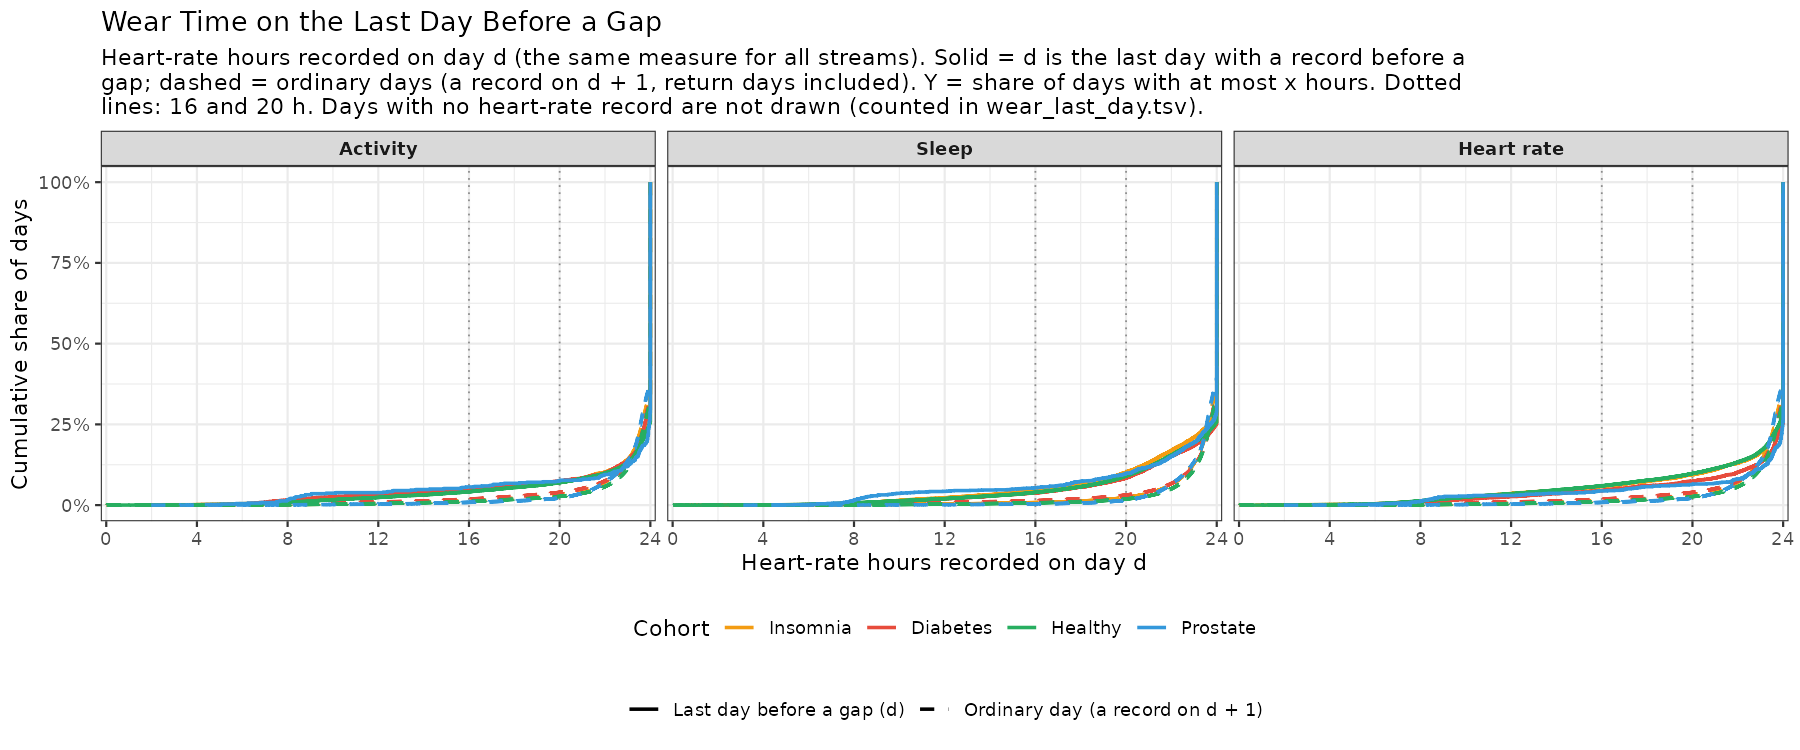

In [7]:
# ==== CELL 11f   (data quality: wear time of the last recorded day before a gap; ~1-2 min, no model; run BEFORE Cell 16 to see whether the analyses wear_ge16h / wear_ge20h matter)
# Wear = heart-rate minutes recorded on the calendar day (the same measure for the activity, sleep and heart-rate streams; a day with no heart-rate record has no wear, is counted and not drawn).
# Figure wear_last_day: ECDF of the hours on day d, solid = d is the last day with a record before a gap, dashed = ordinary days (a record on d + 1; return days included); streams side by side, cohorts in colour.
# Tables wear_last_day_distribution (the ECDF), wear_last_day (median / quartiles, share under 16 h and 20 h with a person-clustered 95% interval, days without a heart-rate record),
# wear_last_day_contrast (last - ordinary: percentage points under each threshold and mean hours, 95% interval, cluster-robust p, Holm over the cohorts).
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "wear")
print(res$wear_last_day[, .(stream, cohort, group, n_days, n_no_hr_record, median_h = round(median_h, 1), threshold_h, pct_below = round(pct_below, 1), low = round(pct_low, 1), high = round(pct_high, 1))])
print(res$wear_last_day_contrast[, .(stream, cohort, quantity, last = round(last, 1), ordinary = round(ordinary, 1), difference = round(difference, 2), p = signif(p, 3), p_holm = signif(p_holm, 3))])
show_figure(OUT_DIR, "wear_last_day")


In [17]:
# 12   the primary test and gap-definition models (the long part: probably around 3 hours)
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "onset",
                                onset_roles = c("primary", "secondary_threshold"),
                                model_streams = "activity")
print(res$primary_test)

18:30:11 | [run] onset / activity / activity|joint|k1|adj  (session 1.5 GB, free 23.7 GB)

18:35:45 | [run] onset / activity / activity|joint|k2|adj  (session 3.4 GB, free 21.9 GB)

18:41:23 | [run] onset / activity / activity|joint|k3|adj  (session 3.4 GB, free 21.9 GB)

18:46:41 | [run] onset / activity / activity|joint|k7|adj  (session 3.4 GB, free 21.9 GB)

18:53:26 | [run] onset_extra / activity / vif  (session 3.4 GB, free 21.9 GB)

18:53:27 | [run] onset_extra / activity / cohort_interaction  (session 3.4 GB, free 21.9 GB)

19:04:13 | [run] onset_extra / activity / cohort_Insomnia  (session 3.4 GB, free 21.9 GB)

19:04:51 | [run] onset_extra / activity / cohort_Diabetes  (session 3.4 GB, free 21.9 GB)

19:05:20 | [run] onset_extra / activity / cohort_Healthy  (session 3.4 GB, free 21.9 GB)

19:09:13 | [run] onset_extra / activity / cohort_Prostate  (session 3.4 GB, free 21.9 GB)

19:09:21 | [run] onset_extra / activity / deciles  (session 3.4 GB, free 21.9 GB)

19:09:23 | [run] 

     stream        term    estimate        or    or_low  or_high            p
     <char>      <char>       <num>     <num>     <num>    <num>        <num>
1: activity w_act_steps -0.09706774 0.9074945 0.8822598 0.933451 1.516416e-11
         p_holm n_events status
          <num>    <int> <char>
1: 1.516416e-11    26642     ok


In [18]:
#13 gap on set model sleep
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "onset",
                                onset_roles = c("primary", "secondary_threshold"),
                                model_streams = "sleep")
print(res$primary_test)

19:13:17 | [run] onset / sleep / sleep|joint|k1|adj  (session 1.5 GB, free 23.3 GB)

19:18:09 | [run] onset / sleep / sleep|joint|k2|adj  (session 3.5 GB, free 21.3 GB)

19:23:02 | [run] onset / sleep / sleep|joint|k3|adj  (session 3.5 GB, free 21.3 GB)

19:27:47 | [run] onset / sleep / sleep|joint|k7|adj  (session 3.5 GB, free 21.3 GB)

19:32:24 | [run] onset_extra / sleep / vif  (session 3.5 GB, free 21.3 GB)

19:32:26 | [run] onset_extra / sleep / cohort_interaction  (session 3.5 GB, free 21.3 GB)

19:42:23 | [run] onset_extra / sleep / cohort_Insomnia  (session 3.5 GB, free 21.4 GB)

19:42:56 | [run] onset_extra / sleep / cohort_Diabetes  (session 3.5 GB, free 21.3 GB)

19:43:25 | [run] onset_extra / sleep / cohort_Healthy  (session 3.5 GB, free 21.3 GB)

19:47:19 | [run] onset_extra / sleep / cohort_Prostate  (session 3.5 GB, free 21.3 GB)

19:47:26 | [run] onset_extra / sleep / deciles  (session 3.5 GB, free 21.3 GB)

19:47:28 | [run] onset_extra / sleep / pre_gap_trajectory  (se

     stream        term     estimate        or    or_low  or_high            p
     <char>      <char>        <num>     <num>     <num>    <num>        <num>
1: activity w_act_steps -0.097067743 0.9074945 0.8822598 0.933451 1.516416e-11
2:    sleep w_act_steps -0.005085217 0.9949277 0.9873297 1.002584 1.935508e-01
         p_holm n_events status
          <num>    <int> <char>
1: 3.032832e-11    26642     ok
2: 1.935508e-01   115046     ok


In [19]:
# 14 gap onset model hr
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "onset",
                                onset_roles = c("primary", "secondary_threshold"),
                                model_streams = "hr")
print(res$primary_test)

19:49:40 | [run] onset / hr / hr|joint|k1|adj  (session 1.5 GB, free 23.2 GB)

19:54:32 | [run] onset / hr / hr|joint|k2|adj  (session 3.3 GB, free 21.5 GB)

19:59:15 | [run] onset / hr / hr|joint|k3|adj  (session 3.3 GB, free 21.5 GB)

20:04:05 | [run] onset / hr / hr|joint|k7|adj  (session 3.3 GB, free 21.5 GB)

20:09:55 | [run] onset_extra / hr / vif  (session 3.3 GB, free 21.5 GB)

20:09:57 | [run] onset_extra / hr / cohort_interaction  (session 3.2 GB, free 21.5 GB)

20:19:23 | [run] onset_extra / hr / cohort_Insomnia  (session 3.2 GB, free 21.6 GB)

20:19:53 | [run] onset_extra / hr / cohort_Diabetes  (session 3.2 GB, free 21.5 GB)

20:20:19 | [run] onset_extra / hr / cohort_Healthy  (session 3.2 GB, free 21.5 GB)

20:23:52 | [run] onset_extra / hr / cohort_Prostate  (session 3.2 GB, free 21.5 GB)

20:23:58 | [run] onset_extra / hr / deciles  (session 3.2 GB, free 21.5 GB)

20:24:00 | [run] onset_extra / hr / pre_gap_trajectory  (session 3.2 GB, free 21.5 GB)

20:24:12 | [run] on

     stream        term     estimate        or    or_low  or_high            p
     <char>      <char>        <num>     <num>     <num>    <num>        <num>
1: activity w_act_steps -0.097067743 0.9074945 0.8822598 0.933451 1.516416e-11
2:       hr w_act_steps -0.014184257 0.9859159 0.9633439 1.009017 2.299976e-01
3:    sleep w_act_steps -0.005085217 0.9949277 0.9873297 1.002584 1.935508e-01
         p_holm n_events status
          <num>    <int> <char>
1: 4.549249e-11    26642     ok
2: 3.871017e-01    41884     ok
3: 3.871017e-01   115046     ok


In [20]:
# 15  Models B and C: 6 independent units per stream (4 x B, 2 x C), each saved on its own. They are built from
# the gaps and one activity predictor only (no person-day table), so they need little memory.
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "gap_models",
                                model_streams = c("activity", "sleep", "hr"))
print(res$model_B_post_gap_activity[, .(stream, model_id, estimate = round(estimate, 3), p = signif(p, 3), status)])
print(res$model_C_gap_length[, .(stream, model_id, or = round(or, 2), po_p = signif(po_p, 2), status)])
cat("failed units:", nrow(res$unit_failures), "\n")      # 0 = nothing failed; otherwise run this cell again to retry them
if (nrow(res$unit_failures) > 0L) print(res$unit_failures)

R_zmq_msg_send errno: 4 strerror: Interrupted system call
num> <char>
 1: activity               B_back1_adj   -0.076 1.94e-49     ok
 2: activity               B_back2_adj   -0.006 1.09e-01     ok
 3: activity       B_back2_adj_dbg_all   -0.005 1.59e-01     ok
 4: activity    B_back2_adj_fullperiod   -0.009 2.53e-02     ok
 5: activity          B_back2_adj_mvpa   -0.006 1.23e-01     ok
 6: activity           B_back2_adj_pre   -0.005 2.32e-01     ok
 7: activity   B_back2_adj_pre_dbg_all    0.004 2.35e-01     ok
 8: activity      B_back2_adj_pre_mvpa   -0.005 2.23e-01     ok
 9: activity  B_back2_adj_pre_same_dbg    0.003 4.20e-01     ok
10: activity B_back2_adj_pre_same_full   -0.005 2.32e-01     ok
11: activity      B_back2_adj_same_dbg   -0.006 1.49e-01     ok
12: activity     B_back2_adj_same_full   -0.006 1.09e-01     ok
13: activity             B_back2_unadj   -0.006 1.49e-01     ok
14:       hr               B_back1_adj   -0.016 5.34e-10     ok
15:       hr               B_back2

In [8]:
# ==== CELL 16   (sensitivity analyses, incl. the NEW full-period standardization; figures per stream: sensitivity_forest_<stream> = within-person
#                predictors under every analysis, sensitivity_all_terms_other_<stream> = ALL terms (incl. the CCI refits cci_removed / cci_as_groups / cci_within_cohort); units saved by an older version are
#                refitted ONCE - this is the long cell)
# NEW: the primary onset model (and the whole onset family) now reads the predictors from the last FULL day d - 1 (the calendar day before d, the last day with a record before a
# gap; the mirror image of the first full day back in model B). The day right before the gap (d, may be a partial day) is a SENSITIVITY analysis: day_before_gap (all rows),
# last_full_day_same_rows / day_before_gap_same_rows / both_days (identical rows); tables day_check, day_descriptive, day_pattern; figures day_check_<stream>, day_pattern_<stream>.
# NEW: wear_ge16h / wear_ge20h = the predictors of day d, only on the rows whose day d has >= 16 / >= 20 hours of heart-rate minutes recorded (all streams; a day with no heart-rate record is excluded);
# the person's usual is the primary one. Table wear_filter_flow (rows, people, events and the mean steps z-score by wear class of d and for the kept rows). Units not yet fitted run; the others are skipped.
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "sensitivity",
                                model_streams = c("activity", "sleep", "hr"))
print(res$sensitivity[, .(stream, analysis, term, or = round(or, 2), p = signif(p, 3), status)])
print(res$day_check[, .(stream, model, or = round(or, 3), low = round(or_low, 3), high = round(or_high, 3), p = signif(p, 3), p_holm = signif(p_holm, 3))])   # last full day d - 1 (primary) vs the day before the gap d
print(res$day_descriptive[, .(stream, quantity, mean_gap = round(mean_gap, 3), mean_no_gap = round(mean_no_gap, 3), difference = round(difference, 3), p = signif(p, 3))])   # steps z-score by gap status; the change d - 1 -> d

18:04:47 | [skip] onset / activity / activity|joint|k1|adj (checkpoint from 2026-11-01 18:35)

18:04:47 | [skip] sensitivity / activity / main (checkpoint from 2026-11-02 03:31)

18:04:47 | [skip] sensitivity / activity / trailing_baseline (checkpoint from 2026-11-02 03:37)

18:04:47 | [skip] sensitivity / activity / exclude_partial_wear (checkpoint from 2026-11-02 03:42)

18:04:47 | [skip] sensitivity / activity / first_gap_only (checkpoint from 2026-11-02 03:46)

18:04:47 | [skip] sensitivity / activity / cci_removed (checkpoint from 2026-11-02 03:51)

18:04:47 | [skip] sensitivity / activity / cci_as_groups (checkpoint from 2026-11-02 03:57)

18:04:47 | [skip] sensitivity / activity / cci_within_cohort (checkpoint from 2026-11-02 04:02)

18:04:47 | [skip] sensitivity / activity / day_before_gap (checkpoint from 2026-11-02 04:08)

18:04:47 | [skip] sensitivity / activity / last_full_day_same_rows (checkpoint from 2026-11-02 04:13)

18:04:47 | [skip] sensitivity / activity / day_befor

      stream                    analysis         term    or         p status
      <char>                      <char>       <char> <num>     <num> <char>
 1: activity                   both_days  w_act_steps  0.58  0.00e+00     ok
 2: activity               cci_as_groups  w_act_steps  0.91  1.63e-11     ok
 3: activity                 cci_removed  w_act_steps  0.91  1.43e-11     ok
 4: activity           cci_within_cohort  w_act_steps  0.91  1.52e-11     ok
 5: activity        cluster_robust_logit  w_act_steps  0.93  5.46e-06     ok
 6: activity           conditional_logit  w_act_steps  0.89  2.63e-13     ok
 7: activity              day_before_gap  w_act_steps  0.65  0.00e+00     ok
 8: activity    day_before_gap_same_rows  w_act_steps  0.65  0.00e+00     ok
 9: activity        exclude_partial_wear  w_act_steps  0.91  2.46e-04     ok
10: activity              first_gap_only  w_act_steps  0.91  1.06e-03     ok
11: activity full_period_standardization  w_act_steps  0.91  1.29e-10     ok

In [5]:
# 17 exploratory on 3000 ppl
cfg_fast <- make_config(list(export  = list(date = EXPORT_DATE),
                             overlap = list(policy = OVERLAP_POLICY),
                             model   = list(exploratory_sample_persons = 3000L)))
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg_fast, OUT_DIR, stages = "onset",
                                onset_roles = "exploratory", model_streams = c("activity", "sleep", "hr"))
print(table(res$onset_models$role, res$onset_models$stream))

17:00:20 | [run] onset / activity / activity|uni_act_steps|k1|unadj  (session 3.1 GB, free 22.4 GB)

17:01:40 | [run] onset / activity / activity|uni_act_steps|k1|adj  (session 3.1 GB, free 22.4 GB)

17:03:16 | [run] onset / activity / activity|uni_act_sedentary|k1|unadj  (session 3.1 GB, free 22.4 GB)

17:04:19 | [run] onset / activity / activity|uni_act_sedentary|k1|adj  (session 3.1 GB, free 22.4 GB)

17:05:44 | [run] onset / activity / activity|uni_act_mvpa|k1|unadj  (session 3.1 GB, free 22.4 GB)

17:06:53 | [run] onset / activity / activity|uni_act_mvpa|k1|adj  (session 3.1 GB, free 22.4 GB)

17:08:24 | [run] onset / activity / activity|joint|k1|unadj  (session 3.1 GB, free 22.4 GB)

17:09:34 | [skip] onset_extra / activity / vif (checkpoint from 2026-11-01 18:53)

17:09:35 | [run] onset / sleep / sleep|own_uni_sleep_inbed|k1|unadj  (session 3.1 GB, free 22.2 GB)

17:10:14 | [run] onset / sleep / sleep|own_uni_sleep_inbed|k1|adj  (session 3.2 GB, free 22.1 GB)

17:11:32 | [run] o

                     
                      activity hr sleep
  exploratory                7 15    15
  primary                    1  1     1
  secondary_threshold        3  3     3


In [6]:
# ==== CELL 18   (run-in analysis, PRIMARY: the onset model, model B and model C on the days / gaps AFTER the first 28 days, without a run-in term and with the run-in AND its interaction; long)
# The description of Cell 11c runs first inside this call. Same rows in both models. Run-in = log2(1 + missing days in the first 28 days), centred, per doubling;
# its interaction is with the steps term (onset, C) / the gap length (B). H1 = run-in effect, H2 = interaction (the confirmatory test, Holm over the streams),
# H3 = does the primary steps effect change. Figures (all prefixed runin_, apart from the main analysis): runin_primary_effect, runin_steps_by_missing_days,
# runin_onset_all_terms_other_<stream>, runin_gapB_all_terms_<stream>, runin_gapC_all_terms_<stream>, and ONE GVIF figure per model: runin_gvif_onset_<stream>,
# runin_gvif_model_B_<stream>, runin_gvif_model_C_<stream>. Other forms of the run-in are in Cell 18b (sensitivity).
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "runin",
                                model_streams = c("activity", "sleep", "hr"))
print(res$runin_tests[analysis == "primary", .(model, stream, hypothesis, term, effect = round(effect, 3), low = round(low, 3), high = round(high, 3), p = signif(p, 3), p_holm = signif(p_holm, 3))])
print(res$runin_primary_effect[variant %in% RUNIN_PRIMARY_VARIANTS, .(model, stream, variant, effect = round(effect, 3))])   # H3: the steps effect without / with the run-in terms
print(res$runin_quality[variant %in% RUNIN_PRIMARY_VARIANTS, .(model, stream, variant, n_people, n_events, events_per_coefficient = round(events_per_coefficient, 1), status, sparse, usable)])
print(res$runin_collinearity[variant == "interaction" & flag != "ok", .(stream, analysis, term, vif_equiv = round(vif_equiv, 1), flag)])   # run-in terms with a high / severe VIF-equivalent
cat("failed units:", nrow(res$unit_failures), "\n")
#for (f_ in list.files(file.path(OUT_DIR, "figures"), pattern = "^runin_(primary|steps_by_missing|gvif)")) show_figure(OUT_DIR, sub("\\.png$", "", f_))


17:40:38 | [skip] runin_extra / activity / describe (checkpoint from 2026-11-01 18:27)

17:40:38 | [run] runin_onset / activity / activity|joint|k1|adj | reference  (session 3.2 GB, free 22.2 GB)

17:45:46 | [run] runin_onset / activity / activity|joint|k1|adj | interaction  (session 3.2 GB, free 22.2 GB)

17:51:38 | [run] runin_gapB / activity / B_back2_adj | reference  (session 3.2 GB, free 22.2 GB)

17:51:47 | [run] runin_gapC / activity / C_adj | reference  (session 3.2 GB, free 22.2 GB)

17:51:55 | [run] runin_gapB / activity / B_back2_adj | interaction  (session 3.2 GB, free 22.2 GB)

17:52:02 | [run] runin_gapC / activity / C_adj | interaction  (session 3.2 GB, free 22.2 GB)

17:52:10 | [skip] runin_extra / sleep / describe (checkpoint from 2026-11-01 18:27)

17:52:10 | [run] runin_onset / sleep / sleep|joint|k1|adj | reference  (session 3.2 GB, free 22.2 GB)

17:56:54 | [run] runin_onset / sleep / sleep|joint|k1|adj | interaction  (session 3.2 GB, free 22.2 GB)

18:02:12 | [run

      model   stream                                 hypothesis
     <char>   <char>                                     <char>
 1:   onset activity H1: run-in missing days -> later gap onset
 2:   onset activity         H2: steps effect depends on run-in
 3:   onset       hr H1: run-in missing days -> later gap onset
 4:   onset       hr         H2: steps effect depends on run-in
 5:   onset    sleep H1: run-in missing days -> later gap onset
 6:   onset    sleep         H2: steps effect depends on run-in
 7: model B activity H1: run-in missing days -> later gap onset
 8: model B activity    H2: gap-length effect depends on run-in
 9: model B       hr H1: run-in missing days -> later gap onset
10: model B       hr    H2: gap-length effect depends on run-in
11: model B    sleep H1: run-in missing days -> later gap onset
12: model B    sleep    H2: gap-length effect depends on run-in
                term effect    low   high         p    p_holm
              <char>  <num>  <num>  <num> 

In [7]:
# ==== CELL 18b  (run-in analysis, SENSITIVITY: the other forms of the run-in - main effect only, run-in as categories (shape check), run-in linear; long)
# Runs the primary units first (finished ones are skipped). Figures (prefix runin_sensitivity_): runin_sensitivity_primary_effect, runin_sensitivity_shape,
# runin_sensitivity_onset_all_terms_other_<stream>, runin_sensitivity_gapB_all_terms_<stream>, runin_sensitivity_gapC_all_terms_<stream>.
# Tests (runin_tests, analysis = "sensitivity"): the likelihood-ratio test of H2 against the main-effect model, H1 / H2 with the linear coding, the shape of the coding.
res <- run_missingness_pipeline(inp$day_tables, inp$persons, cfg, OUT_DIR, stages = "runin_sensitivity",
                                model_streams = c("activity", "sleep", "hr"))
print(res$runin_tests[analysis == "sensitivity", .(model, stream, hypothesis, form, effect = round(effect, 3), p = signif(p, 3), p_holm = signif(p_holm, 3))])
print(res$runin_shape[, .(stream, variant, n_rows, aic = round(aic, 1), delta_aic_vs_main = round(delta_aic_vs_main, 1))])      # coding of the run-in: AIC of every form
cat("failed units:", nrow(res$unit_failures), "\n")


18:14:32 | [skip] runin_extra / activity / describe (checkpoint from 2026-11-01 18:27)

18:14:32 | [skip] runin_onset / activity / activity|joint|k1|adj | reference (checkpoint from 2026-11-02 17:45)

18:14:32 | [skip] runin_onset / activity / activity|joint|k1|adj | interaction (checkpoint from 2026-11-02 17:51)

18:14:32 | [run] runin_onset / activity / activity|joint|k1|adj | main  (session 3.2 GB, free 22.2 GB)

18:20:04 | [run] runin_onset / activity / activity|joint|k1|adj | categorical  (session 3.2 GB, free 22.3 GB)

18:25:15 | [run] runin_onset / activity / activity|joint|k1|adj | linear_interaction  (session 3.2 GB, free 22.3 GB)

18:30:39 | [skip] runin_gapB / activity / B_back2_adj | reference (checkpoint from 2026-11-02 17:51)

18:30:39 | [skip] runin_gapC / activity / C_adj | reference (checkpoint from 2026-11-02 17:51)

18:30:39 | [skip] runin_gapB / activity / B_back2_adj | interaction (checkpoint from 2026-11-02 17:52)

18:30:39 | [skip] runin_gapC / activity / C_adj |

      model   stream                                 hypothesis
     <char>   <char>                                     <char>
 1:   onset activity H1: run-in missing days -> later gap onset
 2:   onset activity         H2: steps effect depends on run-in
 3:   onset activity H1: run-in missing days -> later gap onset
 4:   onset activity         H2: steps effect depends on run-in
 5:   onset activity             Shape: categories vs reference
 6:   onset       hr H1: run-in missing days -> later gap onset
 7:   onset       hr         H2: steps effect depends on run-in
 8:   onset       hr H1: run-in missing days -> later gap onset
 9:   onset       hr         H2: steps effect depends on run-in
10:   onset       hr             Shape: categories vs reference
11:   onset    sleep H1: run-in missing days -> later gap onset
12:   onset    sleep         H2: steps effect depends on run-in
13:   onset    sleep H1: run-in missing days -> later gap onset
14:   onset    sleep         H2: steps e

In [8]:
#19 summarize and copy to busket
CKPT <- file.path(OUT_DIR, cfg$checkpoint$dirname)
print(checkpoint_report(CKPT, cfg)[, .N, by = .(kind, state)])     # valid / stale / failed / corrupt checkpoints
cat(readLines(file.path(OUT_DIR, "results_summary.md")), sep = "\n")
print(list.files(file.path(OUT_DIR, "tables")))
print(list.files(file.path(OUT_DIR, "figures")))                   # figure_captions.md explains every figure
system2("gsutil", c("-m", "cp", "-r", OUT_DIR, file.path(Sys.getenv("WORKSPACE_BUCKET"), "missingness_results/")))

          kind  state     N
        <char> <char> <int>
1:        gapB  valid    42
2:        gapC  valid    24
3:       onset  valid    49
4: onset_extra  valid    27
5: runin_extra  valid     3
6:  runin_gapB  valid     9
7:  runin_gapC  valid     9
8: runin_onset  valid    15
9: sensitivity  valid    52
# Results summary

Written from the saved result tables (no model is refitted).

## Run-in analysis (wear in study days 15-42; only gaps AFTER the run-in are modelled)
Primary analysis (model with the run-in and its interaction). H1: more missing days in the run-in -> later gaps (per doubling of 1 + missing days). H2: the steps effect depends on the run-in (the confirmatory test; Holm over the streams). Other forms of the run-in are in the sensitivity analysis (runin_tests.tsv, analysis = sensitivity).
* onset, activity, H1: 1.14 (1.09-1.19), p = 7.8e-09, Holm p = 7.8e-09
* onset, activity, H2: 0.98 (0.95-1.01), p = 0.2, Holm p = 0.2
* onset, hr, H1: 1.16 (1.14-1.19), p = 1.1e-39, Ho